![Banner](../../../../Images/Banner/03_spatial_analysis/03_04_banner_spatial_analysis_Multi_Criteria.png)



# Fuzzy Suitability for Rasters





Derive terrain criteria from a 90 m DEM, fuzzify them, and combine with fuzzy
overlay operators. Rasters and intermediates are stored under `Data/03_spatial_analysis/MCSM_data/`.

1. [Load and reproject the DEM](#load-and-reproject-the-dem)
   - [1.1 Hillshade for context](#hillshade-for-context)
2. [Deriving terrain criteria](#deriving-terrain-criteria)
   - [2.1 Slope](#slope)
   - [2.2 Aspect: a circular variable](#aspect-a-circular-variable)
   - [2.3 Topographic position index (TPI)](#topographic-position-index-tpi)
   - [2.4 Distance to streams](#distance-to-streams)
3. [Hard constraints](#hard-constraints)
4. [Fuzzification](#fuzzification)
   - [4.1 A conditional membership with fuzzy OR](#a-conditional-membership-with-fuzzy-or)
5. [Fuzzy overlay on rasters](#fuzzy-overlay-on-rasters)
6. [From suitability surface to candidate sites](#from-suitability-surface-to-candidate-sites)
   - [6.1 Choosing the threshold](#choosing-the-threshold)
   - [6.2 Vectorizing the candidate sites](#vectorizing-the-candidate-sites)
   - [6.3 What makes the top sites good?](#what-makes-the-top-sites-good)
7. [Save rasters for Module 8](#save-rasters-for-module-8)
8. [Exercises](#exercises)
9. [Key takeaways](#key-takeaways)




**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README. It also uses `pysheds`, which no GeoLattice option installs: `pip install pysheds`.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup and downloads.
import warnings  # silence benign RuntimeWarnings
from pathlib import Path  # filesystem paths for MCSM sample data

# Third-party numeric / plotting stack used throughout this notebook.
import matplotlib.pyplot as plt  # figure and axes creation for raster maps
import numpy as np  # array ops for DEM derivatives and memberships
import pandas as pd  # tabular summaries of memberships and patches

# ===================================================================
# Locate the repository root, import fuzzy helpers, and load raster I/O libs.
# ===================================================================
# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

DATA_DIR = ROOT / "Data" / "03_spatial_analysis" / "MCSM_data"  # shared MCSM sample-data folder
DATA_DIR.mkdir(parents=True, exist_ok=True)  # create it if missing

warnings.filterwarnings("ignore", category=RuntimeWarning)  # quiet numeric warnings
pd.set_option("display.width", 120)  # wider DataFrame previews
plt.rcParams["figure.figsize"] = [9, 6]  # default figure size for maps

# Import the fuzzy MCSM module and named helpers used below / in exercises.
import geolattice.spatial_analysis.multi_criteria_suitability_analysis as fz  # fuzzy API alias
from geolattice.spatial_analysis.multi_criteria_suitability_analysis import (
    SuitabilityAnalysisError,  # typed error for invalid inputs
    categorical_and,  # Boolean AND helper
    categorical_or,  # Boolean OR helper
    criteria_count,  # k-of-n helper
    hybrid_suitability,  # constrained continuous scores
    jaccard_index,  # set similarity helper
    limiting_criterion,  # weakest-membership helper
    mamdani,  # rule-based FIS (later notebooks)
    minmax_normalize,  # min-max standardisation
    monte_carlo_weights,  # weight uncertainty helper
    overlay,  # fuzzy overlay operators
    percentile_rank_normalize,  # rank-based standardisation
    perturb_weights,  # OAT weight perturbation
    spread_for_small,  # calibrate Small-function spread
    top_quantile_mask,  # top-q Boolean mask
    trapezoidal_mf,  # trapezoid membership
    triangular_mf,  # triangle membership
    weighted_fuzzy_overlay,  # weighted fuzzy operators
    weighted_linear_combination,  # WLC helper
)

# Raster / vector I/O and scientific helpers for DEM processing.
import os  # ensure DATA_DIR exists
import urllib.request  # download sample DEM once
import geopandas as gpd  # candidate site polygons
import rasterio  # GeoTIFF I/O
from rasterio.warp import calculate_default_transform, reproject, Resampling  # DEM reprojection
from rasterio import features  # raster-to-polygon conversion
from scipy import ndimage as ndi  # filters, labeling, distance transforms

os.makedirs(DATA_DIR, exist_ok=True)  # ensure the MCSM data folder exists



## Load and reproject the DEM

The DEM is stored in geographic coordinates (EPSG:4326). Slope and distance calculations need **equal-unit, metric** cell sizes, so the DEM is reprojected to **UTM zone 14N (EPSG:32614)** at 90 m resolution. Bilinear resampling is used because elevation is continuous.

In [2]:
# Download a small Texas DEM (geographic) if missing, then reproject to UTM 14N at 90 m.
DEM_URL = "https://raw.githubusercontent.com/mdbartos/pysheds/master/data/dem.tif"  # sample DEM URL
dem_geo = str(DATA_DIR / "dem_texas_geo.tif")  # local geographic GeoTIFF path
if not Path(dem_geo).is_file():
    urllib.request.urlretrieve(DEM_URL, dem_geo)  # download once, then reuse

# Inspect the source DEM, then warp to a metric CRS for slope/distance work.
with rasterio.open(dem_geo) as src:
    print("CRS:", src.crs, "| size:", src.width, "x", src.height, "| res:", src.res)  # source metadata
    print("Bounds:", [round(b, 4) for b in src.bounds])  # geographic bounds

    DST_CRS, RES = "EPSG:32614", 90  # UTM zone 14N, 90 m cells
    transform, width, height = calculate_default_transform(
        src.crs, DST_CRS, src.width, src.height, *src.bounds, resolution=RES)  # target grid
    dem = np.full((height, width), np.nan, dtype="float32")  # destination elevation array
    reproject(rasterio.band(src, 1), dem,
              src_transform=src.transform, src_crs=src.crs, src_nodata=src.nodata,  # source georef
              dst_transform=transform, dst_crs=DST_CRS, dst_nodata=np.nan,  # destination georef
              resampling=Resampling.bilinear)  # bilinear for continuous elevations

# Shared GeoTIFF profile for saving derived rasters in the same grid.
PROFILE = dict(driver="GTiff", height=height, width=width, count=1, dtype="float32",
               crs=DST_CRS, transform=transform, nodata=np.nan, compress="lzw")  # write template


def save_tif(arr, path):
    """Write a float32 array to GeoTIFF using the shared PROFILE."""
    with rasterio.open(path, "w", **PROFILE) as dst:
        dst.write(arr.astype("float32"), 1)  # band 1


dem_utm = str(DATA_DIR / "dem_texas_utm.tif")  # projected DEM path
save_tif(dem, dem_utm)  # persist the UTM DEM for pysheds
valid = ~np.isnan(dem)  # True where elevation is defined
CELL_HA = RES * RES / 10_000  # cell area in hectares

print(f"Reprojected: {width} x {height} cells of {RES} m | valid cells: {valid.sum():,} "
      f"({valid.sum() * CELL_HA / 100:,.0f} km²)")  # grid summary
print(f"Elevation range: {np.nanmin(dem):.0f}-{np.nanmax(dem):.0f} m")  # elevation range



CRS: EPSG:4326 | size: 367 x 359 | res: (0.0008333333333333, 0.0008333333333333)
Bounds: [-97.485, 32.5225, -97.1792, 32.8217]
Reprojected: 325 x 374 cells of 90 m | valid cells: 117,478 (952 km²)
Elevation range: 147-298 m


The reprojected grid is slightly rotated relative to the original, so a few edge cells become NoData (NaN). Every later calculation must preserve those NaNs.

### Hillshade for context

A **hillshade** simulates illumination from a light source and makes terrain easy to read. It is used as a backdrop for the maps in this module.

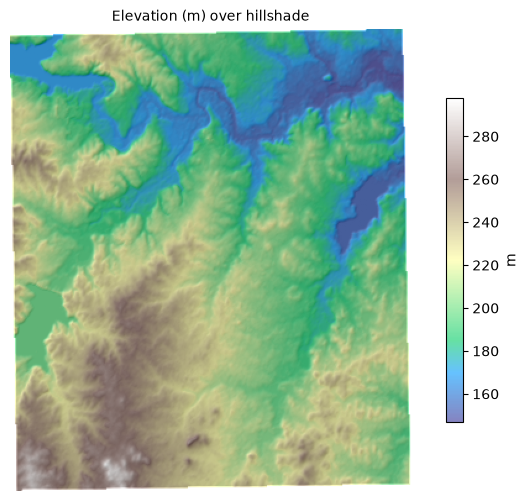

In [3]:
# Build a hillshade and a helper that drapes arrays over it for quick maps.
def hillshade(z, res, azimuth=315, altitude=45):
    """Compute a simple Lambertian hillshade from an elevation array."""
    dy, dx = np.gradient(z, res)  # elevation gradients (row, col)
    slope = np.arctan(np.hypot(dx, dy))  # slope in radians
    aspect = np.arctan2(-dx, dy)  # aspect in radians
    az, alt = np.radians(azimuth), np.radians(altitude)  # light direction
    hs = np.sin(alt) * np.cos(slope) + np.cos(alt) * np.sin(slope) * np.cos(az - aspect)  # illumination
    return np.clip(hs, 0, 1)  # keep hillshade in [0, 1]


hs = hillshade(dem, RES)  # hillshade for basemap context
EXTENT = [transform.c, transform.c + width * RES, transform.f - height * RES, transform.f]  # imshow extent


def show(arr, title, cmap="RdYlGn", vmin=0, vmax=1, label="mu", ax=None, alpha=0.75):
    """Drape an array over hillshade and add a colourbar."""
    ax = ax or plt.gca()  # use current axes if none provided
    ax.imshow(hs, cmap="gray", extent=EXTENT)  # hillshade basemap
    im = ax.imshow(arr, cmap=cmap, vmin=vmin, vmax=vmax, extent=EXTENT, alpha=alpha)  # overlay array
    ax.set_title(title, fontsize=10)  # panel title
    ax.set_axis_off()  # hide ticks
    plt.colorbar(im, ax=ax, shrink=0.7, label=label)  # colourbar
    return ax  # return axes for further drawing


show(dem, "Elevation (m) over hillshade", cmap="terrain",
     vmin=np.nanmin(dem), vmax=np.nanmax(dem), label="m", alpha=0.6)  # elevation preview
plt.show()  # render the figure



## Deriving terrain criteria

### Slope

The slope is computed from the elevation gradient using `numpy.gradient` with the 90 m cell size and expressed in **percent rise**, the usual engineering unit for site grading.

In [4]:
# Derive percent slope from the DEM gradients (metres of rise per metres of run).
dz_dy, dz_dx = np.gradient(dem, RES)  # rows run north -> south; cols west -> east
slope_pct = 100 * np.hypot(dz_dx, dz_dy)  # slope as percent grade

print("Slope percentiles (%):", np.round(np.nanpercentile(slope_pct, [5, 25, 50, 75, 95, 99]), 2))  # slope stats



Slope percentiles (%): [0.25 1.05 1.82 2.9  5.29 8.39]


### Aspect: a circular variable

**Aspect** is the compass direction a slope faces (0° = north, 90° = east, 180° = south). It is **circular**, so 359° and 1° are neighbors. Applying a membership function to raw degrees would be wrong.

The fix is to convert aspect to the **angular deviation from due south** (0-180°) and apply the membership to that. In NumPy array coordinates, rows increase southward, which sets the signs used below.

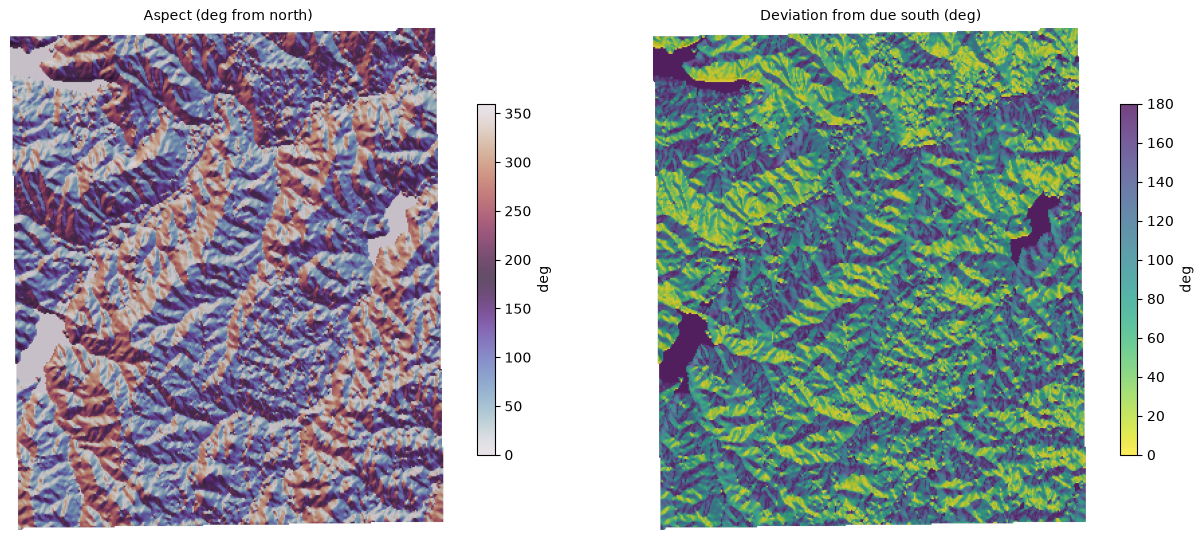

In [5]:
# Aspect as compass bearing of the downslope direction (0 = N, clockwise).
aspect = (np.degrees(np.arctan2(-dz_dx, dz_dy)) + 360) % 360  # aspect in degrees [0, 360)
aspect[np.isnan(dem)] = np.nan  # keep NoData aligned with the DEM

# Angular deviation from south (0 = due south, 180 = due north).
dev_south = np.abs(((aspect - 180 + 180) % 360) - 180)  # circular distance to 180 degrees

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))  # aspect and south-deviation maps
show(aspect, "Aspect (deg from north)", cmap="twilight", vmin=0, vmax=360, label="deg", ax=axes[0])  # aspect
show(dev_south, "Deviation from due south (deg)", cmap="viridis_r", vmin=0, vmax=180, label="deg", ax=axes[1])  # deviation
plt.tight_layout()  # tighten spacing
plt.show()  # render the figure



### Topographic position index (TPI)

The **TPI** is a cell's elevation minus the mean elevation of its neighborhood. Positive values mark ridges and upper slopes, negative values mark valleys and depressions. A 15 × 15 cell window (about 1.35 km) captures landform-scale position.

`scipy.ndimage.uniform_filter` does not handle NaN, so the neighborhood mean is computed as a ratio of two filtered arrays: the sum of valid values divided by the count of valid cells.

TPI percentiles (m): [-6.12 -2.47 -0.23  2.26  6.95]


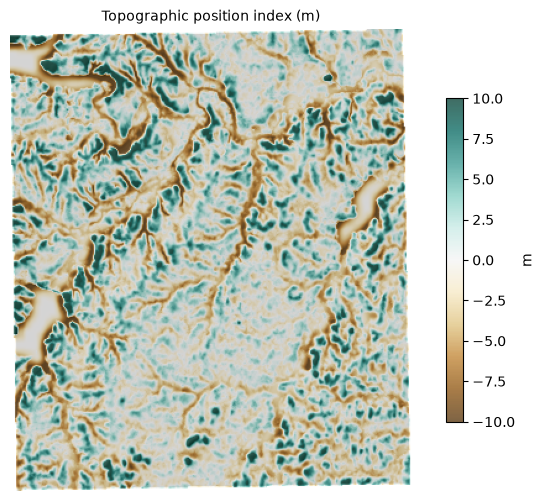

In [6]:
# Topographic Position Index: elevation minus neighbourhood mean elevation.
def nanmean_filter(a, size):
    """Moving-window mean that ignores NaNs by normalising a filled sum by a weight sum."""
    vals = np.where(np.isnan(a), 0, a)  # replace NaN with 0 for summing
    wts = (~np.isnan(a)).astype(float)  # 1 where valid, 0 where NaN
    return ndi.uniform_filter(vals, size) / np.maximum(ndi.uniform_filter(wts, size), 1e-9)  # nan-aware mean


tpi = dem - nanmean_filter(dem, 15)  # 15-cell window TPI (m)
print("TPI percentiles (m):", np.round(np.nanpercentile(tpi, [5, 25, 50, 75, 95]), 2))  # TPI stats

show(tpi, "Topographic position index (m)", cmap="BrBG", vmin=-10, vmax=10, label="m")  # TPI map
plt.show()  # render the figure



### Distance to streams

Stream channels are derived from the DEM with a standard hydrological workflow in `pysheds`:

1. **Condition** the DEM by filling pits and depressions and resolving flats, so water can flow continuously.
2. Compute **D8 flow direction**, which sends each cell's water to its steepest downslope neighbor.
3. Compute **flow accumulation**, the number of upstream cells draining through each cell.
4. Define **streams** as cells draining more than 500 cells (500 × 0.81 ha ≈ 4 km²).

The Euclidean distance from every cell to the nearest stream cell is then computed with `distance_transform_edt`.

> **Compatibility note:** `pysheds` 0.4 calls `np.in1d`, which was removed in NumPy 2.0. The one-line shim below restores it. It has no effect on older NumPy versions.

In [7]:
# Derive streams via pysheds hydrology, then compute Euclidean distance to stream cells.
if not hasattr(np, "in1d"):
    np.in1d = np.isin  # NumPy 2 shim for older pysheds

from pysheds.grid import Grid  # DEM-based flow routing

grid = Grid.from_raster(dem_utm)  # open the projected DEM
r = grid.read_raster(dem_utm)  # read elevation into a pysheds Raster
conditioned = grid.resolve_flats(grid.fill_depressions(grid.fill_pits(r)))  # hydrologically condition
fdir = grid.flowdir(conditioned)  # D8 flow directions
acc = np.asarray(grid.accumulation(fdir), dtype=float)  # upstream accumulation (cells)

STREAM_CELLS = 500  # accumulation threshold defining stream cells
streams = (acc > STREAM_CELLS) & valid  # stream mask on valid land
dist_stream = ndi.distance_transform_edt(~streams) * RES  # metres to nearest stream
dist_stream[~valid] = np.nan  # keep NoData outside the DEM

print(f"Stream cells: {streams.sum():,} ({100 * streams.sum() / valid.sum():.1f}% of area)")  # stream extent
print("Distance-to-stream percentiles (m):", np.round(np.nanpercentile(dist_stream, [5, 25, 50, 75, 95])))  # distance stats



Stream cells: 2,814 (2.4% of area)
Distance-to-stream percentiles (m): [  90.  450.  900. 1498. 2295.]


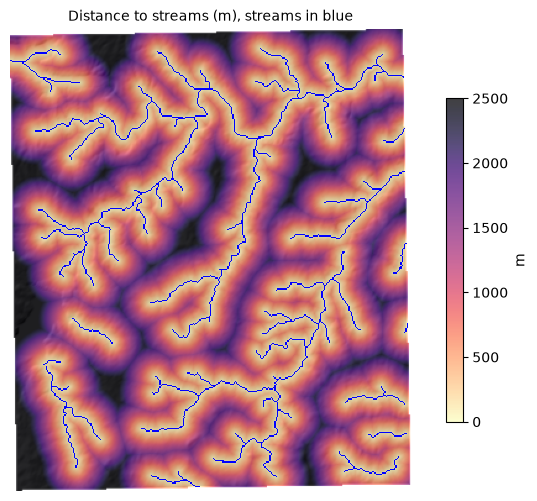

In [8]:
# Map distance to streams and overlay the stream network in blue.
ax = show(dist_stream, "Distance to streams (m), streams in blue", cmap="magma_r",
          vmin=0, vmax=2500, label="m")  # distance surface
ax.imshow(np.where(streams, 1, np.nan), cmap="winter", extent=EXTENT, interpolation="nearest")  # stream overlay
plt.show()  # render the figure



## Hard constraints

Some conditions **exclude** a location no matter how good it is otherwise. These are applied as a crisp Boolean mask, separately from the fuzzy factors:

| Constraint | Rule |
|---|---|
| NoData | Outside the DEM, or edge cells where slope cannot be computed |
| Steep terrain | Slope > 10% (impractical for fixed-tilt arrays) |
| Stream channel and setback | Within 90 m (one cell) of a stream |
| Probable open water | Contiguous areas ≥ 25 ha with slope < 0.1% |

The last rule addresses a common pitfall. **Reservoir surfaces are perfectly flat in a DEM**, so a terrain-only model rates them as ideal solar land. Large, perfectly flat patches are flagged as probable water here. A real project would use a land-cover or hydrography layer such as NLCD or NHD instead.

Probable open water: 6 areas, 23.6 km²
Feasible area: 850.2 km² (89.3% of the study area)


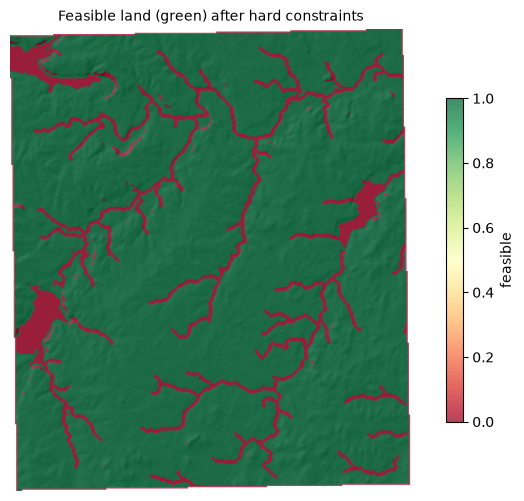

In [9]:
# Hard constraints: exclude water-like flats, steep slopes, stream buffers, and NoData.
flat = np.nan_to_num(slope_pct, nan=99) < 0.1  # near-zero slope candidates
flat_lab, n_flat = ndi.label(flat, structure=np.ones((3, 3)))  # connected flat patches
flat_ha = ndi.sum(flat, flat_lab, np.arange(1, n_flat + 1)) * CELL_HA  # patch areas (ha)
water = np.isin(flat_lab, np.where(flat_ha >= 25)[0] + 1)  # large flat patches (~open water)
print(f"Probable open water: {(flat_ha >= 25).sum()} areas, {water.sum() * CELL_HA / 100:.1f} km²")  # water summary

# Combine hard exclusions into a feasible-land mask.
excluded = (~valid) | np.isnan(slope_pct) | (slope_pct > 10) | (dist_stream <= 90) | water  # exclusion rules
feasible = ~excluded  # True where solar siting is allowed

print(f"Feasible area: {feasible.sum() * CELL_HA / 100:,.1f} km² "
      f"({100 * feasible.sum() / valid.sum():.1f}% of the study area)")  # feasible summary

show(np.where(valid, feasible.astype(float), np.nan), "Feasible land (green) after hard constraints",
     cmap="RdYlGn", label="feasible")  # feasible map
plt.show()  # render the figure



## Fuzzification

| Factor | Function | Parameters | Meaning |
|---|---|---|---|
| Slope | **Small** | midpoint 4%, spread 4 | 2% ≈ 0.94, 4% = 0.5, 8% ≈ 0.06 |
| Aspect | **Gaussian** on deviation from south | midpoint 0°, spread 1.49 × 10⁻⁴ | Due south = 1, east or west (90°) = 0.3, north ≈ 0 |
| Flatness override | **Small** on slope | midpoint 1%, spread 6 | On flat land, aspect does not matter |
| TPI | **Linear** | -6 m → 0, +4 m → 1 | Valley bottoms 0, ridges 1 |
| Distance to streams | **Large** | midpoint 300 m, spread 3 | 90 m ≈ 0.03, 300 m = 0.5, 900 m ≈ 0.96 |

### A conditional membership with fuzzy OR

On a 0.5% slope, aspect is irrelevant because the land is effectively flat and receives full sun. Applying the aspect membership everywhere would wrongly penalize flat, north-tilted fields. This condition is written as a fuzzy rule:

> *Exposure is good if the cell faces south **OR** the cell is flat.*

That rule becomes $\mu_{exposure} = \max(\mu_{south}, \mu_{flat})$. Fuzzy operators can be used *inside* a criterion as well as between criteria.

In [10]:
# Fuzzify the four terrain criteria into membership rasters on [0, 1].
aspect_spread = -np.log(0.3) / 90 ** 2  # gives mu = 0.3 at 90 degrees from south
print(f"Aspect spread = {aspect_spread:.3e}")  # calibrated Gaussian spread

mu_slope = fz.small(slope_pct, 4, 4)  # gentler slopes preferred
mu_south = fz.gaussian(dev_south, 0, aspect_spread)  # prefer south-facing aspects
mu_flat = fz.small(slope_pct, 1, 6)  # very flat land also counts as exposed
mu_exposure = fz.overlay([mu_south, mu_flat], "or")  # south-facing OR nearly flat
mu_tpi = fz.linear(tpi, -6, 4)  # prefer mid-slope / lower positions
mu_stream = fz.large(dist_stream, 300, 3)  # prefer greater distance from streams

MEMBERSHIPS = {"Slope": mu_slope, "Exposure": mu_exposure, "Topographic position": mu_tpi,
               "Stream distance": mu_stream}  # named membership rasters

pd.DataFrame({k: pd.Series(v[valid]).describe() for k, v in MEMBERSHIPS.items()}).round(3)  # membership stats



Aspect spread = 1.486e-04


,Slope,Exposure,Topographic position,Stream distance
count,116171.000,116171.000,117478.000,117478.000
mean,0.838,0.511,0.572,0.792
std,0.241,0.364,0.302,0.317
min,0.002,0.008,0.000,0.000
25%,0.783,0.145,0.353,0.771
50%,0.959,0.490,0.577,0.964
75%,0.995,0.900,0.826,0.992
max,1.000,1.000,1.000,1.000


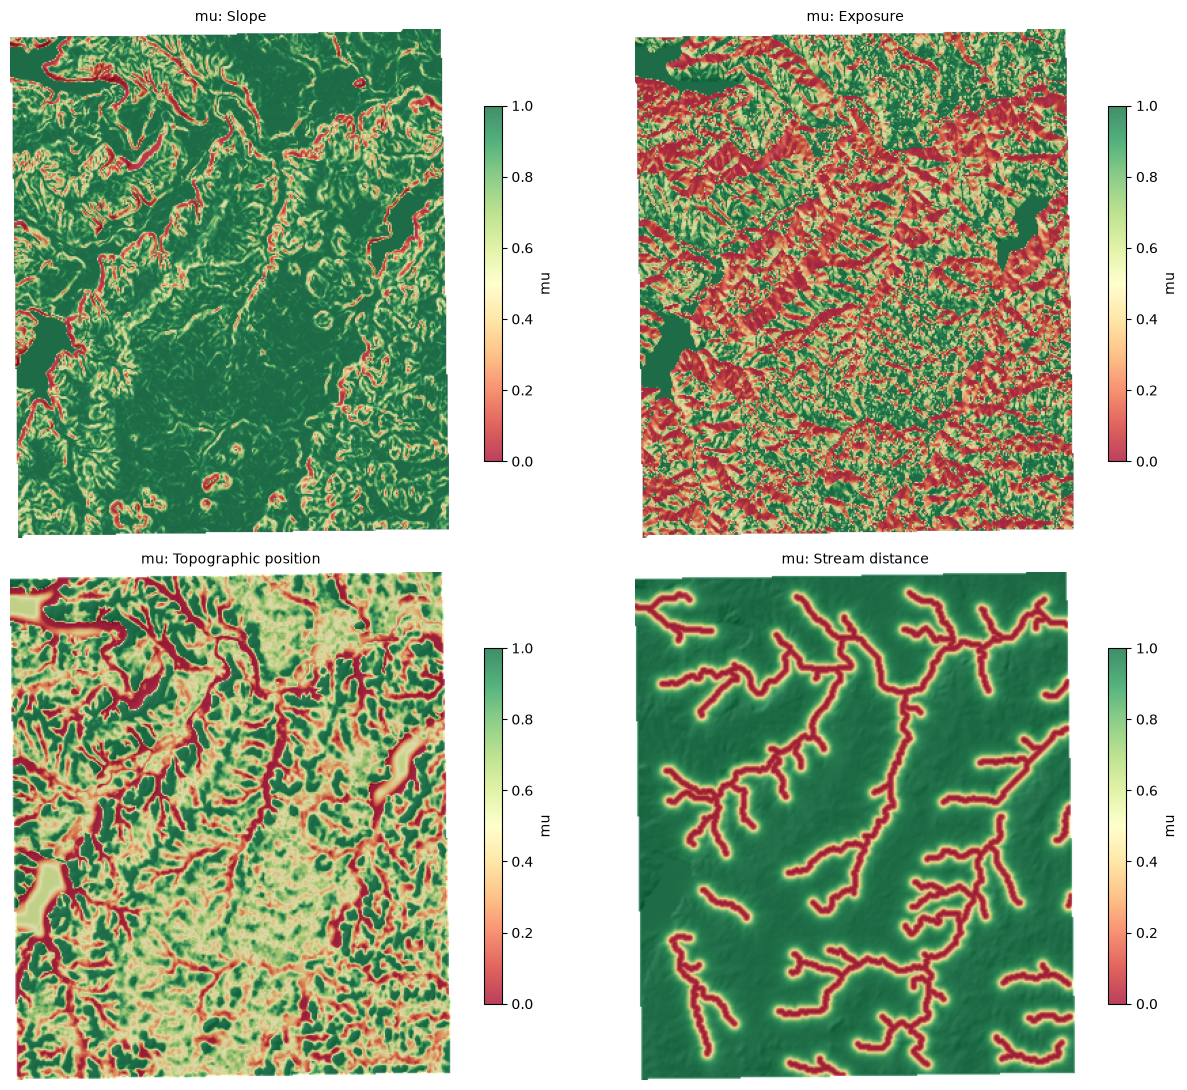

In [11]:
# Map the four fuzzy membership rasters over hillshade.
fig, axes = plt.subplots(2, 2, figsize=(13, 11))  # 2x2 membership maps
for ax, (name, mu) in zip(axes.ravel(), MEMBERSHIPS.items()):
    show(mu, f"mu: {name}", ax=ax)  # membership overlay
plt.tight_layout()  # tighten spacing
plt.show()  # render the figure



The exposure map shows the flatness override at work. Gently sloping, north-facing land keeps a high μ_exposure, while only the *steeper* north-facing valley sides are penalized.

## Fuzzy overlay on rasters

`multi_criteria_suitability_analysis.overlay()` works on whole NumPy arrays, so combining 120,000 cells takes one function call per operator. The constraint mask is applied **after** overlay by setting excluded cells to NaN.



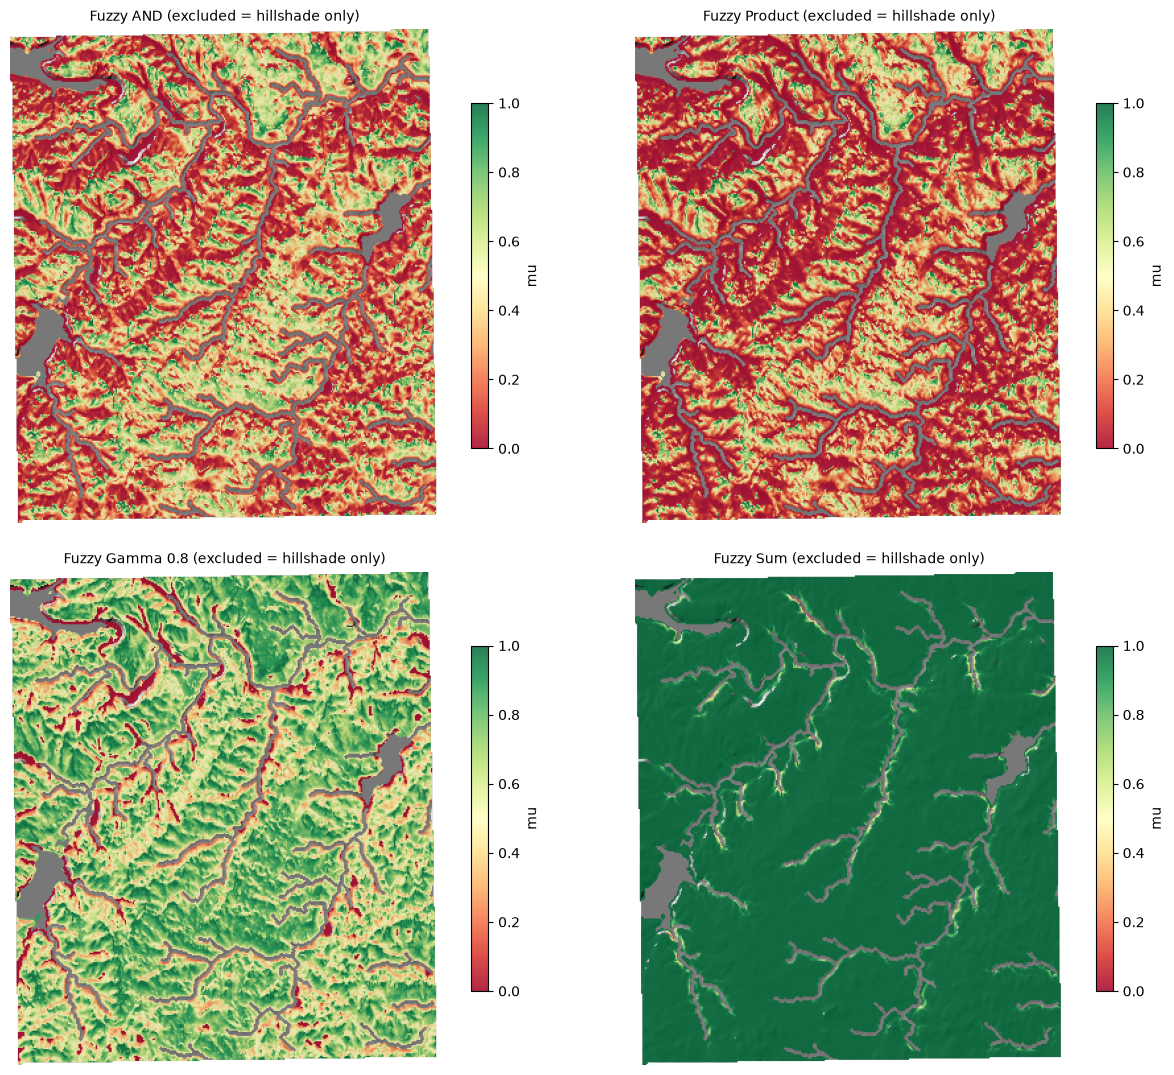

,AND,Product,Gamma 0.8,Sum
count,104961.000,104961.000,104961.000,104961.000
mean,0.320,0.226,0.632,0.991
std,0.260,0.241,0.233,0.040
min,0.000,0.000,0.000,0.147
25%,0.083,0.027,0.485,0.999
50%,0.263,0.132,0.666,1.000
75%,0.511,0.366,0.818,1.000
max,0.999,0.999,1.000,1.000


In [12]:
# Combine memberships with several fuzzy overlay operators and mask to feasible land.
mus = list(MEMBERSHIPS.values())  # membership arrays in a fixed order

results = {
    "AND":       fz.overlay(mus, "and"),  # min (most conservative)
    "Product":   fz.overlay(mus, "product"),  # algebraic product
    "Gamma 0.8": fz.overlay(mus, "gamma", gamma=0.8),  # working gamma blend
    "Sum":       fz.overlay(mus, "sum"),  # algebraic sum
}
results = {k: np.where(feasible, v, np.nan) for k, v in results.items()}  # hide excluded cells

fig, axes = plt.subplots(2, 2, figsize=(13, 11))  # four operator maps
for ax, (name, arr) in zip(axes.ravel(), results.items()):
    show(arr, f"Fuzzy {name} (excluded = hillshade only)", ax=ax, alpha=0.85)  # suitability surface
plt.tight_layout()  # tighten spacing
plt.show()  # render the figure

pd.DataFrame({k: pd.Series(v[feasible]).describe() for k, v in results.items()}).round(3)  # score stats



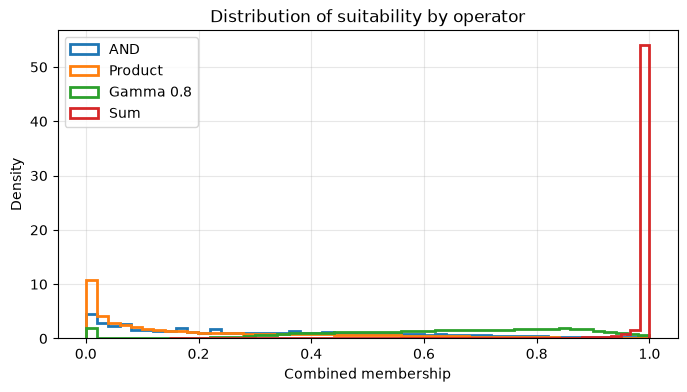

In [13]:
# Compare suitability score distributions across overlay operators (feasible cells only).
fig, ax = plt.subplots(figsize=(8, 4))  # density comparison
for name, arr in results.items():
    ax.hist(arr[feasible], bins=50, histtype="step", lw=2, label=name, density=True)  # score density
ax.set(xlabel="Combined membership", ylabel="Density", title="Distribution of suitability by operator")  # labels
ax.legend(); ax.grid(alpha=0.3)  # legend and light grid
plt.show()  # render the figure



The pattern from Module 6 appears again at the raster scale. **Sum** saturates near 1, while **Product** pushes most cells toward 0. **AND** and **Gamma 0.8** spread values across the range, which makes them the most useful operators for siting. The rest of this module uses **Gamma 0.8** as the suitability surface.

## From suitability surface to candidate sites

A solar farm needs a **contiguous** block of good land, not scattered pixels. This step is the open-source equivalent of ArcGIS *Locate Regions* in its simplest form:

1. **Threshold** the suitability surface to define "highly suitable" land.
2. **Label** connected regions with 8-neighbor connectivity (`scipy.ndimage.label`).
3. **Filter** regions by a minimum area, here 40 ha, roughly a 5-8 MW array.
4. **Rank** regions by mean suitability and area.
5. **Vectorize** regions to polygons for mapping and reporting.

### Choosing the threshold

The threshold should produce **distinct, appropriately sized** patches. If it is too low, highly suitable land merges into one huge, unhelpful region. If it is too high, too few patches remain. The table below compares several thresholds.

In [14]:
# Threshold sensitivity: how patch count/size change as the suitability cut rises.
suit = results["Gamma 0.8"]  # working suitability surface

rows = []  # one summary row per threshold
for t in [0.6, 0.7, 0.8, 0.85, 0.9]:
    h = np.nan_to_num(suit) >= t  # high-suitability binary mask
    lab, k = ndi.label(h, structure=np.ones((3, 3)))  # connected patches
    sizes = ndi.sum(h, lab, np.arange(1, k + 1)) * CELL_HA  # patch sizes in hectares
    rows.append({"threshold": t, "area_km2": h.sum() * CELL_HA / 100,
                 "% of feasible": 100 * h.sum() / feasible.sum(),
                 "patches >= 40 ha": int((sizes >= 40).sum()), "largest patch (ha)": sizes.max()})  # stats
pd.DataFrame(rows).round({"area_km2": 1, "% of feasible": 1, "largest patch (ha)": 0})  # threshold table



,threshold,area_km2,% of feasible,patches >= 40 ha,largest patch (ha)
0,0.60,509.4,59.9,51,23531.0
1,0.70,381.2,44.8,82,11265.0
2,0.80,240.0,28.2,114,1920.0
3,0.85,162.5,19.1,95,510.0
4,0.90,87.9,10.3,34,140.0


At 0.6 and 0.7, highly suitable land merges into patches of more than 10,000 ha, which is too coarse to compare sites. A threshold of **0.85** keeps about a fifth of the feasible land and splits it into about 100 separate candidate patches, so it is used below.

In [15]:
# Extract contiguous high-suitability patches and rank them by quality x log(area).
THRESH, MIN_HA = 0.85, 40  # membership threshold and minimum patch size (ha)

high = np.nan_to_num(suit) >= THRESH  # binary high-suitability mask
labels, n = ndi.label(high, structure=np.ones((3, 3)))  # label connected patches

ids = np.arange(1, n + 1)  # patch ids
cells = ndi.sum(high, labels, ids)  # cell counts per patch
mean_mu = ndi.mean(np.nan_to_num(suit), labels, ids)  # mean suitability per patch

regions = pd.DataFrame({"region": ids, "area_ha": cells * CELL_HA, "mean_mu": mean_mu})  # patch table
regions = regions[regions["area_ha"] >= MIN_HA].copy()  # drop undersized patches
regions["score"] = regions["mean_mu"] * np.log(regions["area_ha"])  # favour large AND good
regions = regions.sort_values("score", ascending=False).reset_index(drop=True)  # rank patches
regions["site"] = np.arange(1, len(regions) + 1)  # site numbers 1..N

print(f"Highly suitable cells: {high.sum():,} ({high.sum() * CELL_HA / 100:.1f} km²) in {n} patches")  # summary
print(f"Patches >= {MIN_HA} ha: {len(regions)}")  # retained patch count
regions.head(10).round(3)  # top 10 candidate patches



Highly suitable cells: 20,061 (162.5 km²) in 1086 patches
Patches >= 40 ha: 95


,region,area_ha,mean_mu,score,site
0,80,507.06,0.911,5.675,1
1,8,510.30,0.906,5.650,2
2,707,477.90,0.906,5.589,3
3,815,420.39,0.916,5.531,4
4,7,400.95,0.913,5.470,5
5,724,438.21,0.897,5.458,6
6,79,249.48,0.924,5.098,7
7,12,233.28,0.924,5.039,8
8,318,233.28,0.919,5.013,9
9,290,153.90,0.929,4.679,10


The ranking score combines quality and size, $\bar\mu \times \ln(\text{area})$. The logarithm rewards larger sites with diminishing returns, so a huge mediocre site cannot dominate. Other rules are possible, such as the highest mean, the largest area above a quality floor, or an optimization model (Part III).

### Vectorizing the candidate sites

In [16]:
# Polygonize retained patches and save candidate solar sites to a GeoPackage.
keep = np.isin(labels, regions["region"]).astype("uint8")  # mask of retained patch labels
shapes = features.shapes(np.where(keep, labels, 0).astype("int32"), mask=keep.astype(bool), transform=transform)  # polygons

sites = gpd.GeoDataFrame(
    [{"region": int(v), "geometry": __import__("shapely.geometry", fromlist=["shape"]).shape(g)} for g, v in shapes],
    crs=DST_CRS).dissolve(by="region").reset_index()  # one multipolygon per region
sites = sites.merge(regions, on="region").sort_values("site")  # attach area / score / site id
sites.to_file(str(DATA_DIR / "solar_candidate_sites.gpkg"), driver="GPKG")  # write candidates
sites[["site", "area_ha", "mean_mu", "score"]].round(3).head(10)  # preview top sites



,site,area_ha,mean_mu,score
15,1,507.06,0.911,5.675
3,2,510.30,0.906,5.650
67,3,477.90,0.906,5.589
80,4,420.39,0.916,5.531
2,5,400.95,0.913,5.470
69,6,438.21,0.897,5.458
14,7,249.48,0.924,5.098
4,8,233.28,0.924,5.039
34,9,233.28,0.919,5.013
31,10,153.90,0.929,4.679


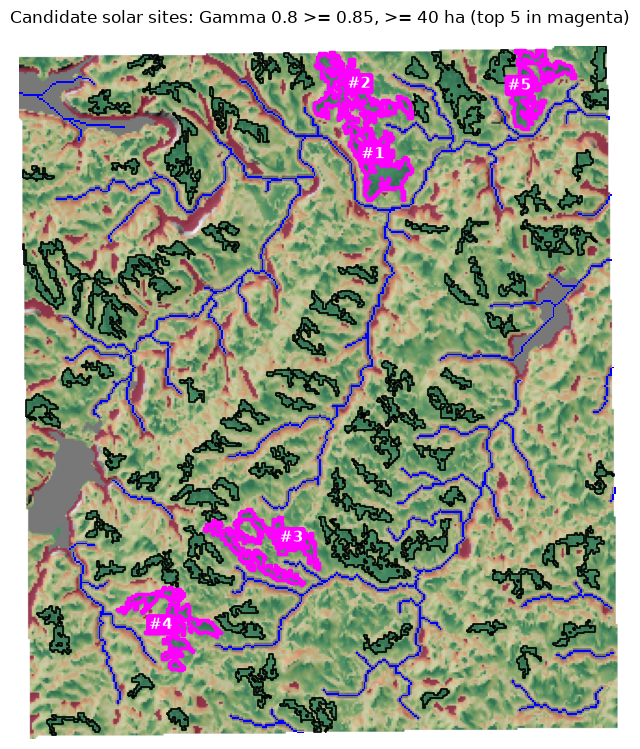

In [17]:
# Map the suitability surface with all candidate boundaries and highlight the top 5.
fig, ax = plt.subplots(figsize=(10, 9))  # candidate-site overview
ax.imshow(hs, cmap="gray", extent=EXTENT)  # hillshade basemap
ax.imshow(suit, cmap="RdYlGn", vmin=0, vmax=1, extent=EXTENT, alpha=0.55)  # suitability drape
ax.imshow(np.where(streams, 1, np.nan), cmap="winter", extent=EXTENT, interpolation="nearest")  # streams
sites.boundary.plot(ax=ax, color="black", linewidth=1.2)  # all candidate outlines
top5 = sites[sites["site"] <= 5]  # top five by ranking score
top5.boundary.plot(ax=ax, color="magenta", linewidth=2.5)  # emphasise top 5
for _, s in top5.iterrows():
    p = s.geometry.representative_point()  # label anchor
    ax.annotate(f"#{s['site']}", (p.x, p.y), color="white", fontsize=11, fontweight="bold",
                ha="center", bbox=dict(boxstyle="round,pad=0.2", fc="magenta", ec="none"))  # site label
ax.set_title(f"Candidate solar sites: Gamma 0.8 >= {THRESH}, >= {MIN_HA} ha (top 5 in magenta)")  # title
ax.set_axis_off()  # hide ticks
plt.show()  # render the figure



### What makes the top sites good?

Average memberships within each top site show **why** it ranks highly and which factor is weakest. This is the raster version of the limiting-criterion analysis in Module 6.

In [18]:
# Profile why the top sites rank highly: mean memberships and key terrain stats.
profile = {}  # one column per top site
for _, s in regions.head(5).iterrows():
    m = labels == s["region"]  # cells belonging to this patch
    profile[f"Site #{int(s['site'])}"] = {name: np.nanmean(mu[m]) for name, mu in MEMBERSHIPS.items()} | {
        "Area (ha)": s["area_ha"], "Mean slope (%)": np.nanmean(slope_pct[m]),
        "Mean dist. to stream (m)": np.nanmean(dist_stream[m])}  # membership + terrain summary
pd.DataFrame(profile).round(2)  # site comparison table



,Site #1,Site #2,Site #3,Site #4,Site #5
Slope,0.98,0.99,0.99,0.97,0.97
Exposure,0.90,0.92,0.90,0.90,0.91
Topographic position,0.77,0.71,0.76,0.78,0.78
Stream distance,0.96,0.98,0.93,0.98,0.96
Area (ha),507.06,510.30,477.90,420.39,400.95
Mean slope (%),1.00,0.89,1.02,1.20,1.23
Mean dist. to stream (m),1052.81,1608.28,1018.16,1520.15,1325.65


All five top sites are nearly flat (about 1% slope), well exposed, and more than 1 km from streams. **Topographic position** is the weakest factor at every one of them (μ ≈ 0.7-0.8). These are broad uplands rather than distinct ridges. Without the open-water constraint in Section 3, a reservoir surface (mean slope 0.01%) ranks among the top three sites. You can check this by removing `water` from the constraint mask.

## Save rasters for Module 8

In [19]:
# Save intermediate rasters/arrays for the advanced fuzzy notebook (Module 8).
np.savez_compressed(str(DATA_DIR / "solar_layers.npz"),
                    dem=dem, hs=hs, slope_pct=slope_pct, dev_south=dev_south, tpi=tpi,
                    dist_stream=dist_stream, streams=streams, feasible=feasible,
                    mu_slope=mu_slope, mu_exposure=mu_exposure, mu_tpi=mu_tpi, mu_stream=mu_stream,
                    extent=np.array(EXTENT))  # compressed NumPy archive of key layers
save_tif(suit, str(DATA_DIR / "solar_suitability_gamma08.tif"))  # working suitability GeoTIFF
print("Saved solar_layers.npz and solar_suitability_gamma08.tif")  # confirm exports



Saved solar_layers.npz and solar_suitability_gamma08.tif


## Exercises

1. Change the stream threshold from 500 to 2,000 cells. How do the stream network, the feasible area, and the top sites change?
2. Replace the TPI window of 15 cells with 7 and with 31 cells. Which landforms does each scale capture?
3. Remove the flatness override (use `mu_south` directly). Quantify the loss of highly suitable area.
4. Rank sites by mean μ alone, and then by area alone. Which ranking would you defend to an investor?
5. Write a function `locate_sites(suit, thresh, min_ha)` that returns the site GeoDataFrame, and test a threshold of 0.6.

## Key takeaways

- Derive terrain criteria from a DEM in a **projected, metric CRS**, and keep NoData as NaN throughout.
- **Circular variables** such as aspect need conversion (deviation from a target direction) before fuzzification.
- Fuzzy operators can build **conditional criteria** inside a factor, such as *south-facing OR flat*.
- Keep **hard constraints** crisp and **soft factors** fuzzy, and apply the mask after overlay.
- Thresholding, connected-component labeling, area filtering, and vectorization turn a surface into **actionable candidate sites**.

**Next: Module 8: Advanced Fuzzy Suitability: sensitivity, weighting, and rule-based fuzzy inference.**